# 04 · Generación con un LLM local: con RAG y sin RAG

**Objetivo:** cargar un modelo instructivo **pequeño**, pensado para CPU
(`Qwen/Qwen2.5-0.5B-Instruct`, unos 0,5B de parámetros), y comparar la misma
pregunta en dos condiciones:

- **Sin RAG:** el modelo responde «de memoria». Con una empresa ficticia y con
  convenios del curso, es fácil que **alucine** (invente 30 días de vacaciones,
  un puerto 8000, un nombre que no está en el corpus…).
- **Con RAG:** recuperamos k fragmentos, se los pasamos en el *prompt* y le
  pedimos que se atenga a ellos y cite fuentes. Si no está en el contexto, debe
  abstenerse.

Este modelo es didáctico, no es un LLM de producción. Se equivocará al redactar
incluso con buen contexto. Lo que nos importa es ver el contraste: sin fuentes,
inventa; con fuentes, se acerca a los hechos o se calla.

Si el 0,5B no cabe en memoria, `rag_utils` intenta un modelo de reserva
(`SmolLM2-135M-Instruct`), más pobre en español pero más ligero.


In [1]:
from pathlib import Path
import os, sys, json, time, gc, textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "rag_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de RAG "
        "(src/rag_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from rag_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    modo_rapido,
    guardar_json,
    cargar_json,
    cargar_corpus,
    cargar_preguntas,
    fragmentar_documentos,
    resumen_fragmentos,
    Codificador,
    similitud_coseno,
    IndiceNumpy,
    IndiceFAISS,
    IndiceBM25,
    fusion_rrf,
    Reranker,
    evaluar_recuperacion,
    construir_mensajes,
    construir_contexto,
    GeneradorLocal,
    contiene_hechos,
    parece_abstencion,
    PipelineRAG,
    evaluar_fidelidad,
    MODELO_EMBEDDINGS_DEFECTO,
    MODELO_RERANKER_DEFECTO,
    MODELO_LLM_DEFECTO,
    MODELO_LLM_RESERVA,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
MODO_RAPIDO = modo_rapido(True)
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")
print(f"Modo rapido: {MODO_RAPIDO}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/rag/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/rag
Dispositivo: cpu
Semilla:     42
Modo rapido: True


In [2]:
# --- Mandos de este cuaderno ---
MODELO_EMB = MODELO_EMBEDDINGS_DEFECTO
MODELO_LLM = MODELO_LLM_DEFECTO
K = 4
MAX_NUEVOS = 64 if MODO_RAPIDO else 120
# En modo rapido basta un puñado de preguntas representativas.
IDS_DEMO = ["q11", "q13", "q03", "q19"] if MODO_RAPIDO else ["q11", "q13", "q03", "q05", "q10", "q19", "q20"]
print(f"LLM={MODELO_LLM}  k={K}  max_nuevos={MAX_NUEVOS}")
print("Preguntas de esta demo:", IDS_DEMO)


LLM=Qwen/Qwen2.5-0.5B-Instruct  k=4  max_nuevos=64
Preguntas de esta demo: ['q11', 'q13', 'q03', 'q19']


## 1. Índice, embeddings y LLM

Cargamos el índice del cuaderno 02, el codificador y el LLM. La primera vez, el
LLM ocupa del orden de 1 GB en disco (más si hay varios archivos de pesos). En
CPU, cada respuesta puede tardar **varios segundos**. Es normal.


In [3]:
indice = IndiceFAISS.cargar(RUTAS["modelos"] / "indice_faiss")
indice_bm25 = IndiceBM25(indice.fragmentos)
codificador = Codificador(MODELO_EMB, dispositivo_destino=str(DEVICE))
preguntas = cargar_preguntas(RUTAS["datos"] / "preguntas.json")
por_id = {p["id"]: p for p in preguntas}
demo = [por_id[i] for i in IDS_DEMO if i in por_id]
print(f"Fragmentos indexados: {len(indice.fragmentos)}")
print(f"Preguntas en la demo: {len(demo)}")

t0 = time.perf_counter()
generador = GeneradorLocal(
    MODELO_LLM,
    dispositivo_destino=str(DEVICE),
    reserva=MODELO_LLM_RESERVA,
)
t_llm = time.perf_counter() - t0
print(f"LLM cargado: {generador.nombre}  dtype={generador.dtype_nombre}  en {t_llm:.1f} s")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

/workspace/rag/src/rag_utils.py:594: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.dim = int(self.modelo.get_sentence_embedding_dimension())


Fragmentos indexados: 77
Preguntas en la demo: 4


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

LLM cargado: Qwen/Qwen2.5-0.5B-Instruct  dtype=torch.float32  en 0.9 s


## 2. La plantilla del *prompt*

Con RAG, el sistema le prohíbe inventar y le pide citas `[doc::#n]`. El usuario
recibe el contexto (fragmentos ya seleccionados) y la pregunta. Sin RAG, solo
va la pregunta: es el control de la comparación.


In [4]:
# Un ejemplo de prompt CON contexto, sin generar todavía
pregunta_ejemplo = demo[0]["pregunta"]
qv = codificador.codificar([pregunta_ejemplo], progreso=False)[0]
hits = indice.buscar(qv, k=K)
mensajes_con = construir_mensajes(pregunta_ejemplo, hits, con_rag=True)
mensajes_sin = construir_mensajes(pregunta_ejemplo, None, con_rag=False)

print("===== SISTEMA (con RAG) =====")
print(mensajes_con[0]["content"])
print("\n===== USUARIO (con RAG, recortado a 1200 caracteres) =====")
print(mensajes_con[1]["content"][:1200])
print("\n===== USUARIO (sin RAG) =====")
print(mensajes_sin[1]["content"])


===== SISTEMA (con RAG) =====
Eres un asistente del curso taller 'De Modelo a Producción' (UNTRM). Respondes SOLO con la información del contexto que se te proporciona. Si la respuesta no está en el contexto, di exactamente: 'No encuentro esa información en los documentos.' Cita el identificador del fragmento entre corchetes, por ejemplo [guia-docker::#1]. No inventes cifras, nombres, fechas ni políticas. Sé breve (3 a 6 frases).

===== USUARIO (con RAG, recortado a 1200 caracteres) =====
Contexto:
[nubeandina-vacaciones-y-trabajo::#1] NubeAndina: vacaciones, presencialidad y trabajo remoto
jornada completa tiene **22 días laborables** de vacaciones al año.
A ellos se suman **3 días** de **«cierre andino»** en **julio**, fijos para toda la
empresa: no descuentan del saldo de 22 días. El cierre andino de 2026 se comunica
cada enero; no es un puente móvil elegido por la persona.

Las vacaciones de más de cinco días laborables seguidos se solicitan con **15 días
naturales** de

[nubeandin

## 3. La misma pregunta, con y sin RAG

Para cada pregunta de la demo generamos las dos respuestas. Debajo medimos si
los **hechos** de referencia aparecen en el texto (una comprobación simple, no
un juez semántico) y si, en las preguntas «no está en el corpus», el modelo se
abstiene.


In [5]:
pipeline = PipelineRAG(
    codificador=codificador,
    indice_denso=indice,
    indice_bm25=indice_bm25,
    generador=generador,
    k=K,
    metodo="hibrido",
)

filas = []
for p in demo:
    print("=" * 70)
    print(f"{p['id']}: {p['pregunta']}")
    sin = pipeline.preguntar(p["pregunta"], con_rag=False, max_nuevos=MAX_NUEVOS)
    con = pipeline.preguntar(p["pregunta"], con_rag=True, max_nuevos=MAX_NUEVOS)
    print("\n--- SIN RAG ({:.1f} s) ---".format(sin["latencias_s"]["total"]))
    print(sin["respuesta"])
    print("\n--- CON RAG ({:.1f} s, fuentes: {}) ---".format(
        con["latencias_s"]["total"], ", ".join(con["docs_fuentes"])
    ))
    print(con["respuesta"])
    if p.get("tipo") == "no_esta":
        cob_sin, cob_con = float(parece_abstencion(sin["respuesta"])), float(parece_abstencion(con["respuesta"]))
        det_sin = {"abstencion": bool(cob_sin)}
        det_con = {"abstencion": bool(cob_con)}
    else:
        det_sin = contiene_hechos(sin["respuesta"], p.get("hechos") or [])
        det_con = contiene_hechos(con["respuesta"], p.get("hechos") or [])
        cob_sin, cob_con = det_sin["cobertura"], det_con["cobertura"]
    print(f"\nCobertura de hechos  sin RAG={cob_sin:.2f}  con RAG={cob_con:.2f}")
    filas.append({
        "id": p["id"],
        "tipo": p.get("tipo"),
        "pregunta": p["pregunta"],
        "respuesta_sin_rag": sin["respuesta"],
        "respuesta_con_rag": con["respuesta"],
        "fuentes": con["docs_fuentes"],
        "cobertura_sin": cob_sin,
        "cobertura_con": cob_con,
        "latencia_sin_s": sin["latencias_s"]["total"],
        "latencia_con_s": con["latencias_s"]["total"],
        "latencia_recuperacion_s": con["latencias_s"]["recuperacion"],
        "latencia_generacion_s": con["latencias_s"]["generacion"],
        "hechos": p.get("hechos") or [],
    })

tabla = pd.DataFrame(filas)
tabla[["id", "tipo", "cobertura_sin", "cobertura_con", "latencia_sin_s", "latencia_con_s", "fuentes"]]


q11: ¿Cuántos días laborables de vacaciones tiene un empleado de NubeAndina y qué es el cierre andino?



--- SIN RAG (77.8 s) ---
Un empleado de NubeAndina puede tener 15 días de vacaciones totales. El cierre andino se refiere al proceso de cancelación de las horas extras que se realizan en el trabajo por parte de los empleados.

--- CON RAG (94.2 s, fuentes: nubeandina-vacaciones-y-trabajo, nubeandina-vacaciones-y-trabajo, nubeandina-vacaciones-y-trabajo, nubeandina-vacaciones-y-trabajo) ---
Un empleado de NubeAndina tiene 22 días laborables de vacaciones al año. El cierre andino de 2026 se comunica cada enero y no es un puente móvil elegido por la persona.

Cobertura de hechos  sin RAG=0.00  con RAG=0.33
q13: ¿Quién es la Delegada de Protección de Datos de NubeAndina y cuál es la longitud mínima de las contraseñas?



--- SIN RAG (69.6 s) ---
La Delegada de Protección de Datos de NubeAndina es María José García. La longitud mínima de las contraseñas que se deben utilizar para acceder a esta función es de 12 caracteres.

--- CON RAG (29.4 s, fuentes: nubeandina-datos-y-seguridad, nubeandina-datos-y-seguridad, nubeandina-datos-y-seguridad, nubeandina-datos-y-seguridad) ---
Longitud mínima de contraseña: 14 caracteres.

Cobertura de hechos  sin RAG=0.00  con RAG=0.50
q03: ¿Cómo se llama la imagen Docker de la API de ejemplo y en qué puerto escucha?



--- SIN RAG (38.0 s) ---
La imagen Docker de la API de ejemplo está llamada "docker" y está configurada para escuchar en el puerto 80.

--- CON RAG (0.7 s, fuentes: guia-docker, guia-docker, guia-kubernetes, guia-docker) ---
retencion-api:local

Cobertura de hechos  sin RAG=0.00  con RAG=0.50
q19: ¿Cuál es el número de teléfono de la cafetería de la sede de NubeAndina en Chachapoyas?



--- SIN RAG (1.3 s) ---
El número de teléfono de la cafetería de la sede de NubeAndina en Chachapoyas es 0123456789.

--- CON RAG (0.9 s, fuentes: nubeandina-empresa, nubeandina-empresa, nubeandina-empresa, curso-reglamento) ---
No encuentro esa información en los documentos.

Cobertura de hechos  sin RAG=0.00  con RAG=1.00


,id,tipo,cobertura_sin,cobertura_con,latencia_sin_s,latencia_con_s,fuentes
0,q11,hecho,0.0,0.333333,77.8466,94.2098,"[nubeandina-vacaciones-y-trabajo, nubeandina-v..."
1,q13,hecho,0.0,0.500000,69.5577,29.4238,"[nubeandina-datos-y-seguridad, nubeandina-dato..."
2,q03,hecho,0.0,0.500000,38.0010,0.6555,"[guia-docker, guia-docker, guia-kubernetes, gu..."
3,q19,no_esta,0.0,1.000000,1.3380,0.8783,"[nubeandina-empresa, nubeandina-empresa, nubea..."


## 4. Lectura de los resultados

En las preguntas de tipo «hecho», una cobertura más alta **con RAG** es la señal
que buscamos: el texto menciona las cifras o los nombres del corpus. En las de
tipo «no_esta» (teléfono de una cafetería que no existe en los documentos, o un
sueldo que no se publica), el éxito es **abstenerse**, no acertar un número.

El modelo de 0,5B a veces redacta torpe o se deja un hecho aunque el fragmento
esté en el *prompt*. Eso no anula la lección: el fallo pasa a ser de generación,
no de desconocimiento total. En producción se usaría un modelo más capaz, o una
API, **con el mismo patrón de recuperación**.


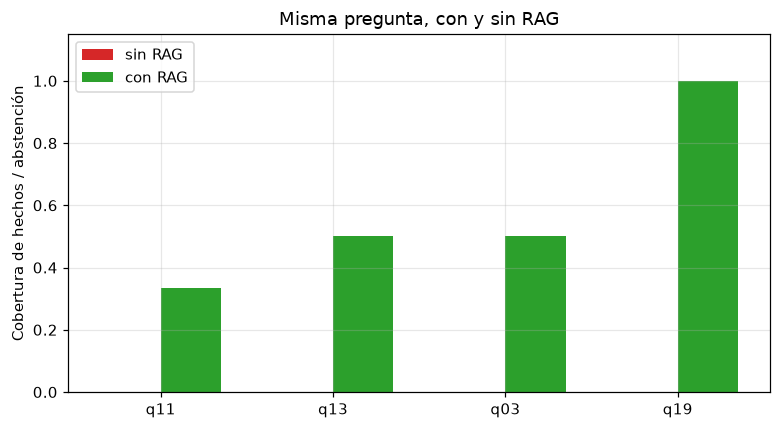

Cobertura media  sin RAG: 0.00   con RAG: 0.58
Latencia media   sin RAG: 46.7s  con RAG: 31.3s (recup 0.53s + gen 30.8s)


In [6]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
x = np.arange(len(tabla))
w = 0.35
ax.bar(x - w/2, tabla["cobertura_sin"].fillna(0), w, label="sin RAG", color="#d62728")
ax.bar(x + w/2, tabla["cobertura_con"].fillna(0), w, label="con RAG", color="#2ca02c")
ax.set_xticks(x)
ax.set_xticklabels(tabla["id"], rotation=0)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Cobertura de hechos / abstención")
ax.set_title("Misma pregunta, con y sin RAG")
ax.legend()
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_con_sin_rag.png", dpi=130)
plt.show()

print(
    "Cobertura media  sin RAG: {:.2f}   con RAG: {:.2f}".format(
        tabla["cobertura_sin"].mean(), tabla["cobertura_con"].mean()
    )
)
print(
    "Latencia media   sin RAG: {:.1f}s  con RAG: {:.1f}s (recup {:.2f}s + gen {:.1f}s)".format(
        tabla["latencia_sin_s"].mean(),
        tabla["latencia_con_s"].mean(),
        tabla["latencia_recuperacion_s"].mean(),
        tabla["latencia_generacion_s"].mean(),
    )
)


## 5. Alternativas por API (opcionales, de pago)

Esta serie **no exige ninguna API de pago**. Si en tu práctica o en un proyecto
real quieres un generador más capaz, el *pipeline* es el mismo: recuperas
fragmentos aquí (CPU, FAISS, tu corpus) y cambias solo el paso de generación
por un cliente de OpenAI, Gemini, Claude, o un *endpoint* de tu empresa. El
contexto y las citas siguen siendo tuyos. Cuida no enviar datos privados a un
proveedor que no esté acordado (en el corpus de NubeAndina, de hecho, está
prohibido).


In [7]:
guardar_json(
    {
        "modelo_llm": generador.nombre,
        "modelo_embeddings": MODELO_EMB,
        "k": K,
        "max_nuevos": MAX_NUEVOS,
        "segundos_carga_llm": round(t_llm, 3),
        "cobertura_media_sin": float(tabla["cobertura_sin"].mean()),
        "cobertura_media_con": float(tabla["cobertura_con"].mean()),
        "latencia_media_sin_s": float(tabla["latencia_sin_s"].mean()),
        "latencia_media_con_s": float(tabla["latencia_con_s"].mean()),
        "detalle": filas,
    },
    RUTAS["resultados"] / "generacion.json",
)
print("Resultados escritos en resultados/generacion.json")
print("Siguiente cuaderno: 05-pipeline-completo-y-evaluacion.")


Resultados escritos en resultados/generacion.json
Siguiente cuaderno: 05-pipeline-completo-y-evaluacion.


## Recapitulando

- El *prompt* es parte del sistema: «responde solo con el contexto» no es un adorno.
- Sin RAG, un LLM pequeño (y muchos grandes) inventan políticas y cifras.
- Con RAG, la calidad depende de la recuperación **y** de que el modelo respete
  el contexto. Por eso evaluamos las dos cosas.

Siguiente: [05-pipeline-completo-y-evaluacion.ipynb](05-pipeline-completo-y-evaluacion.ipynb).
